# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [1]:
# Antes de iniciar es necesario instalar las siguientes librerías:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [3]:
# Ahora si importamos la dataset de iris 
iris = load_iris()
type(iris)

sklearn.utils._bunch.Bunch

In [4]:
# Defino mis variables
X = iris.data
y = iris.target

In [5]:
# Denotar las dimensiones de X y y, instancias y características
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


In [6]:
n_instancias = X.shape[0]
n_caracteristicas = X.shape[1]

print("Instancias:", n_instancias)
print("Características:", n_caracteristicas)

Instancias: 150
Características: 4


In [7]:
# Explramos las características de la dataset
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [8]:
# Conectamos con la dataset de iris y la convertimos en un DataFrame de pandas
df_iris = pd.DataFrame(data=X, columns=iris.feature_names)

In [9]:
# verificamos las primeras filas del DataFrame
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [10]:
# Ahora con Y
iris.target_names


array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [11]:
np.unique(y)

array([0, 1, 2])

In [12]:
# Hacemos un breve cuenta
clases, cantidades = np.unique(y, return_counts=True)
print("Clases:", clases)
print("Cantidades:", cantidades)

Clases: [0 1 2]
Cantidades: [50 50 50]


In [13]:
# Continuamos la tabla con la columna donde se guarda cada flor
df_iris['clase_id'] = y

In [14]:
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase_id
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [15]:
df_iris["especie"] = [iris.target_names[i] for i in y]

In [16]:
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase_id,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [17]:
# Distribución de las clases
conteo_clases = df_iris['especie'].value_counts()
conteo_clases


especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

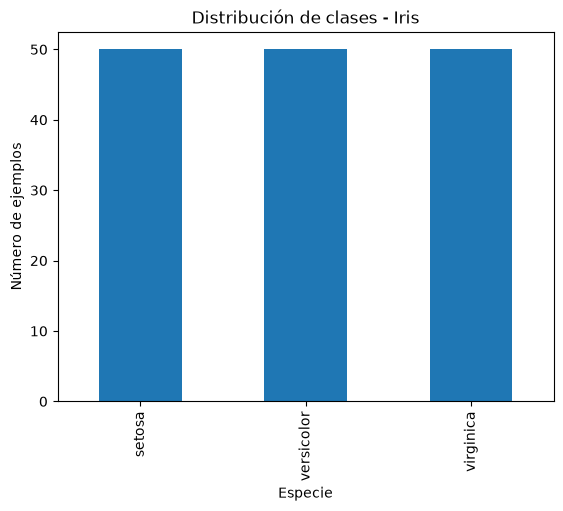

In [18]:
# Grafica
conteo_clases.plot(kind="bar")

plt.xlabel("Especie")
plt.ylabel("Número de ejemplos")
plt.title("Distribución de clases - Iris")
plt.show()

## Interpretación del dataset Iris. 
Cada instancia representa una flor Iris descrita mediante cuatro características: longitud y ancho del sépalo, y longitud y ancho del pétalo. El dataset contiene 150 instancias y 4 características, con tres clases: setosa, versicolor y virginica. Cada clase contiene 50 ejemplos, por lo que el conjunto está balanceado. La matriz X tiene dimensión (150, 4) y el vector de etiquetas y tiene dimensión (150,).

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

## Predicciones iniciales
1. Regresión logística, SVM y MLP son sensibles al escalamiento porque sus parámetros, márgenes u optimización dependen de las magnitudes de las características. Los modelos basados en árboles son mucho menos sensibles al escalamiento.
2. SVM lineal, ya que tiene una frontera lineal en el espacio original, para saberlo debe ser el mas parecido a
$w^{T}x+b=0$.
3. No podemos decir cual sera mejor por ser sofisticado o complejo, dependera del ruido, datos, cantidades, representación, hiperparametros, regularizacion, el mejor modelo se determinara mediante la evaluación sobre datos no utilizados para entrenarlo es decir la generalización

In [19]:
# Importamos la librería de scikit-learn para dividir el dataset en entrenamiento y prueba
from sklearn.model_selection import train_test_split

In [20]:
# Dividimos el dataset en entrenamiento y prueba, usando un 70% para entrenamiento y un 30% para prueba. PERO DEBEMOS USARLA DOS VECES, YA QUE TENEMOS TRES PARTICIONES. PRIMERO DIVIDIMOS EN ENTRENAMIENTO Y TEMPORAL, Y LUEGO DIVIDIMOS TEMPORAL EN VALIDACIÓN Y PRUEBA.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [21]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [22]:
# Observamos si se mantuvieron balanceadas las clases
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (105, 4) (105,)
Validation: (22, 4) (22,)
Test: (23, 4) (23,)


In [23]:
print("Train:", np.bincount(y_train))
print("Validation:", np.bincount(y_val))
print("Test:", np.bincount(y_test))

Train: [35 35 35]
Validation: [8 7 7]
Test: [7 8 8]


In [24]:
# Continuamos con el escalamiento con una pipeline de scikit-learn, que nos permite encadenar varias transformaciones y un estimador final. En este caso, vamos a escalar los datos y luego aplicar un clasificador.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


In [25]:
# Creacion de modelos, primero probamos con regresion logística, que es un modelo lineal para clasificación.
from sklearn.linear_model import LogisticRegression

In [26]:
# Adecuamos a nuestro pipeline
modelo_logistico = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [27]:
modelo_logistico.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [28]:
# Prediccion
y_pred_val = modelo_logistico.predict(X_val)

In [29]:
# Metrica de evaluación acuracy
from sklearn.metrics import accuracy_score



In [30]:
accuracy = accuracy_score(y_val, y_pred_val)
print("Accuracy:", accuracy)

Accuracy: 0.8636363636363636


In [31]:
# Metrica de evaluacion f1-score
from sklearn.metrics import f1_score


In [32]:
f1 = f1_score(
    y_val,
    y_pred_val,
    average="macro"
)

print("F1 macro:", f1)

F1 macro: 0.8564102564102565


Nota: primero creamos un pipeline para ver si era funcional, esto nos servira para sentar la base para los 6 modelos restantes

In [33]:
# Importo los otros clasificadores a usar
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

In [34]:
# Construyo un diccionario de modelos
modelos = {
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "SVM lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", random_state=42))
    ]),

    "Árbol": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(10,),
            max_iter=2000,
            random_state=42
        ))
    ])
}

In [35]:
# Ahora solo recorremos el diccionario de modelos, entrenamos y evaluamos cada modelo, y guardamos los resultados en un DataFrame de pandas.
resultados_val = []
for nombre_modelo, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred_val = modelo.predict(X_val)
    accuracy = accuracy_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val, average="macro")
    resultados_val.append({
        "Modelo": nombre_modelo,
        "Accuracy": accuracy,
        "F1 macro": f1
    })

In [36]:
# Convierto los resultados en una tabla
df_resultados_val = pd.DataFrame(resultados_val)
df_resultados_val


,Modelo,Accuracy,F1 macro
0,Naive Bayes,0.863636,0.856410
1,Logística,0.863636,0.856410
2,SVM lineal,0.863636,0.856410
3,Árbol,0.954545,0.952137
4,Random Forest,0.863636,0.856410
5,Gradient Boosting,0.909091,0.902778
6,MLP,0.909091,0.904762


In [37]:
# Podemos ordenar por desempeño: 
df_resultados_val.sort_values(
    by="F1 macro",
    ascending=False
)

,Modelo,Accuracy,F1 macro
3,Árbol,0.954545,0.952137
6,MLP,0.909091,0.904762
5,Gradient Boosting,0.909091,0.902778
2,SVM lineal,0.863636,0.856410
1,Logística,0.863636,0.856410
0,Naive Bayes,0.863636,0.856410
4,Random Forest,0.863636,0.856410


En la configuración inicial, el modelo con mayor F1 macro
de validación fue Árbol con un valor de 0.952137. Pero aun falta la evaluacion final sobre prueba

In [38]:
# Realizamos segun lo indicado unos ajustes limtados usando solamente validacion, por ejemplo en SVM lineal, podemos ajustar el parámetro C, que controla la regularización. Vamos a probar con C=0.1, C=1 y C=10.

for C in [0.1, 1, 10]:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", C=C))
    ])

    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_val)

    print(
        "C =", C,
        "F1 =", f1_score(y_val, pred, average="macro")
    )

C = 0.1 F1 = 0.8564102564102565
C = 1 F1 = 0.8564102564102565
C = 10 F1 = 0.8564102564102565


In [39]:
# prueba ahora en arboles
for profundidad in [2, 3, 5, None]:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=profundidad,
            random_state=42
        ))
    ])

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_val)

    f1 = f1_score(
        y_val,
        pred,
        average="macro"
    )

    print(profundidad, f1)

2 0.9047619047619048
3 0.9521367521367522
5 0.9047619047619048
None 0.9047619047619048


In [40]:
# Para MLP, podemos ajustar el número de neuronas en la capa oculta. Vamos a probar con 5, 10 y 20 neuronas.
for neuronas in [5, 10, 20]:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(neuronas,),
            max_iter=2000,
            random_state=42
        ))
    ])

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_val)

    f1 = f1_score(
        y_val,
        pred,
        average="macro"
    )

    print(neuronas, f1)

5 0.9521367521367522
10 0.9047619047619048
20 0.9047619047619048


Ahora elegimos.
SVM:
C = 0.1, no hubo cambios en los 3

Árbol:
max_depth = 3, mejor macro

MLP:
hidden_layer_sizes = 5 neuronas, mejor macro


In [41]:
# Ahora si podemos usar el test, y construimos la tabla solicitada con modelo, transformaciones, hiperparámetros y accuracy prueba, f1 macro prueba, congelando los modelos.
# Configuraciones finales congeladas después de usar validación

modelos_finales = {
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ]),

    "Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "SVM lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", C=0.1))
    ]),

    "Árbol": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(5,),
            max_iter=2000,
            random_state=42
        ))
    ])
}





In [42]:
resultados_test = []
predicciones_test = {}

hiperparametros = {
    "Naive Bayes": "GaussianNB por defecto",
    "Logística": "max_iter=1000",
    "SVM lineal": "kernel=lineal, C=0.1",
    "Árbol": "max_depth=3",
    "Random Forest": "n_estimators=100",
    "Gradient Boosting": "configuración por defecto",
    "MLP": "hidden_layer_sizes=(5,), max_iter=2000"
}

for nombre, modelo in modelos_finales.items():

    # Aprende solamente con entrenamiento
    modelo.fit(X_train, y_train)

    # Test se utiliza aquí por primera vez para evaluación final
    pred_test = modelo.predict(X_test)

    # Guardamos predicciones porque luego sirven
    # para las matrices de confusión
    predicciones_test[nombre] = pred_test

    acc = accuracy_score(y_test, pred_test)
    f1 = f1_score(y_test, pred_test, average="macro")

    resultados_test.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": hiperparametros[nombre],
        "Accuracy de prueba": acc,
        "F1 macro de prueba": f1
    })

In [43]:
df_resultados_test = pd.DataFrame(resultados_test)

df_resultados_test

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Naive Bayes,StandardScaler,GaussianNB por defecto,0.956522,0.958170
1,Logística,StandardScaler,max_iter=1000,0.956522,0.958170
2,SVM lineal,StandardScaler,"kernel=lineal, C=0.1",0.956522,0.958170
3,Árbol,StandardScaler,max_depth=3,1.000000,1.000000
4,Random Forest,StandardScaler,n_estimators=100,0.913043,0.915344
5,Gradient Boosting,StandardScaler,configuración por defecto,0.956522,0.958170
6,MLP,StandardScaler,"hidden_layer_sizes=(5,), max_iter=2000",1.000000,1.000000


Hay que notar que en esta partición concreta de prueba, Árbol y MLP obtuvieron el mejor desempeño. Pero porque hay solamente 23 ejemplos en test, por lo que una diferencia de un único error ya modifica el accuracy aproximadamente:
$
\frac{1}{23}\approx 4.35\%
$
Eso explica por qué las diferencias parecen grandes.

In [44]:
# Creacion de la matriz de confusion
from sklearn.metrics import ConfusionMatrixDisplay

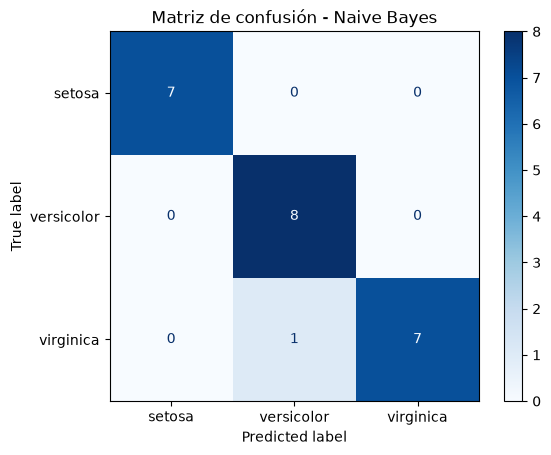

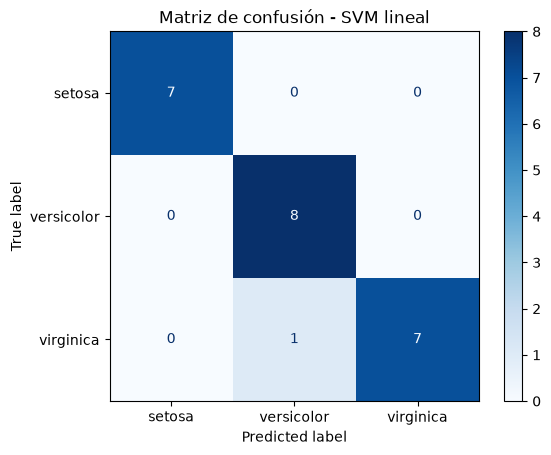

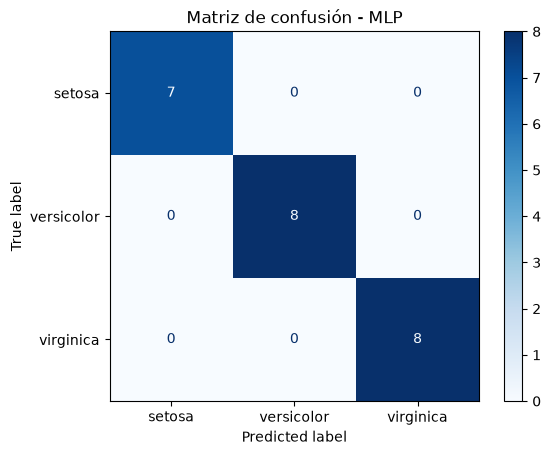

In [45]:
for nombre in ["Naive Bayes", "SVM lineal", "MLP"]:

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones_test[nombre],
        display_labels=iris.target_names,
        cmap="Blues"
    )

    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

## Interpretación de los clasificadores

¿Cuál tuvo mejor desempeño?

En la partición de prueba utilizada, el Árbol de Decisión y el MLP obtuvieron el mejor desempeño, con accuracy y F1 macro iguales a 1.0. Sin embargo, el conjunto de prueba contiene solo 23 instancias, por lo que este resultado no demuestra que estos modelos sean superiores en general. Solo describe su comportamiento en este experimento y partición.

¿Cuál fue el más sencillo de programar?

Gaussian Naive Bayes fue el modelo más sencillo de configurar, ya que prácticamente no requirió definir hiperparámetros para este experimento. Todos los clasificadores compartieron la misma estructura general de fit, predict y evaluación.


¿Accuracy y F1 macro cuentan la misma historia?

Accuracy y F1 macro muestran prácticamente el mismo orden de desempeño. Esto ocurre en parte porque Iris está balanceado y los errores entre clases son pocos. Sin embargo, no son métricas equivalentes: accuracy mide la proporción global de aciertos, mientras que F1 macro calcula F1 independientemente para cada clase y luego las promedia dando el mismo peso a todas.

Macro vs Micro

Macro calcula la métrica para cada clase por separado y después obtiene el promedio, por lo que cada clase tiene el mismo peso. Micro suma primero los aciertos y errores de todas las clases y calcula después la métrica global, por lo que las clases con más ejemplos influyen más.

¿Qué aporta MLP frente a un modelo lineal?

El MLP incorpora capas ocultas y funciones de activación no lineales, por lo que puede aprender representaciones y fronteras de decisión más complejas que un modelo lineal. Esta mayor flexibilidad también implica más parámetros, hiperparámetros y dificultad de entrenamiento, por lo que no garantiza automáticamente mejor generalización.

In [46]:
# Los dos errores de clasificacion

pred_rf = predicciones_test["Random Forest"]

indices_error = np.where(pred_rf != y_test)[0]

print("Índices con error dentro de X_test:", indices_error)

Índices con error dentro de X_test: [ 2 15]


In [47]:
errores_rf = pd.DataFrame(
    X_test[indices_error],
    columns=iris.feature_names
)

errores_rf["Clase real"] = [
    iris.target_names[i]
    for i in y_test[indices_error]
]

errores_rf["Clase predicha"] = [
    iris.target_names[i]
    for i in pred_rf[indices_error]
]

errores_rf

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase real,Clase predicha
0,6.1,2.6,5.6,1.4,virginica,versicolor
1,6.0,3.0,4.8,1.8,virginica,versicolor


Los dos errores de Random Forest corresponden a flores virginica clasificadas como versicolor. Sus características se encuentran en una región donde ambas clases presentan valores relativamente próximos, por lo que existe cierto solapamiento en el espacio de características.

A partir de estos casos podemos observar que las instancias están próximas a características compartidas por ambas clases, pero no podemos afirmar causalmente que una característica concreta sea responsable del error. Tampoco podemos concluir que exista un error de medición o que la etiqueta real sea incorrecta sin evidencia adicional.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [48]:
# Cargar el conjunto de datos Diabetes
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

X_reg = diabetes.data
y_reg = diabetes.target

In [49]:
# Observamos la data
print("Dimensión X:", X_reg.shape)
print("Dimensión y:", y_reg.shape)

print("\nCaracterísticas:")
print(diabetes.feature_names)

Dimensión X: (442, 10)
Dimensión y: (442,)

Características:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [50]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

Problema: regresión supervisada porque disponemos de características X y queremos predecir un objetivo numérico continuo y.
El objetivo y representa una medida cuantitativa de progresión de la diabetes un año después de la medición inicial.

In [51]:
df_diabetes = pd.DataFrame(
    X_reg,
    columns=diabetes.feature_names
)

df_diabetes["target"] = y_reg

df_diabetes.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Las características del dataset ya están transformadas/escaladas; sus números no deben interpretarse directamente como las unidades clínicas originales.

## Análisis de la prediccion inicial

1. ¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos?

No necesariamente, un modelo más flexible puede ajustarse mejor a relaciones complejar y disminuir el error de entrenamiento, pero también puede aprender ruido o particularidades del conjunto de entrenamiento. Por ello, su desempeño debe evaluarse sobre validación y prueba.

In [52]:
# Dividimos el dataset para regresion
X_train_reg, X_temp_reg, y_train_reg, y_temp_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=42
)

In [53]:
# Para nuestros temporales para validación y prueba, usamos un 50% para cada uno
X_val_reg, X_test_reg, y_val_reg, y_test_reg = train_test_split(
    X_temp_reg,
    y_temp_reg,
    test_size=0.50,
    random_state=42
)

In [54]:
# Probamos la particion correcta de datos
print("Train:", X_train_reg.shape, y_train_reg.shape)
print("Validation:", X_val_reg.shape, y_val_reg.shape)
print("Test:", X_test_reg.shape, y_test_reg.shape)

Train: (309, 10) (309,)
Validation: (66, 10) (66,)
Test: (67, 10) (67,)


In [55]:
# Como ahora tendremos error de tipo continuo, vamos a usar métricas de regresión, como el error cuadrático medio (MSE) y el coeficiente de determinación (R^2), importamos las librerías necesarias.
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

MAE y RMSE miden cuánto nos equivocamos; R² mide cuánto mejora el modelo respecto a un baseline basado en la media.

In [56]:
#Definimos una funcion para evaluar y no repetir el mismo código varias veces, que recibe un modelo, los datos de entrada y salida, y devuelve las métricas de evaluación.
def evaluar_regresion(modelo, X, y):
    pred = modelo.predict(X)

    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    r2 = r2_score(y, pred)

    return mae, rmse, r2

In [57]:
# Importamos las librerías necesarias para los modelos de regresión
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

In [58]:
# Configuracion inicial de los modelos
modelos_reg = {

    "Lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, max_iter=10000))
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, max_iter=10000))
    ]),

    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ]),

    "Árbol": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(
            max_depth=3,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(20,),
            max_iter=3000,
            random_state=42
        ))
    ])
}

In [59]:
# Tabla de validación
resultados_val_reg = []

for nombre, modelo in modelos_reg.items():

    modelo.fit(X_train_reg, y_train_reg)

    mae, rmse, r2 = evaluar_regresion(
        modelo,
        X_val_reg,
        y_val_reg
    )

    resultados_val_reg.append({
        "Modelo": nombre,
        "MAE validación": mae,
        "RMSE validación": rmse,
        "R² validación": r2
    })

df_val_reg = pd.DataFrame(resultados_val_reg)

df_val_reg.sort_values("RMSE validación")

c:\Users\Cesarbmm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE validación,RMSE validación,R² validación
2,Lasso,37.944710,48.847962,0.533398
1,Ridge,38.071002,49.795013,0.515129
7,MLP,38.167492,49.957878,0.511953
0,Lineal,38.216681,49.993212,0.511262
5,Random Forest,39.810455,52.829972,0.454223
6,Gradient Boosting,42.441953,53.413773,0.442095
3,kNN,42.687879,55.382018,0.400220
4,Árbol,41.855953,56.413441,0.377672


In [60]:
# Experimento de ajuste de hiperparámetros para Ridge 

alphas = [0.01, 0.1, 1, 10, 100]

resultados_ridge = []

for alpha in alphas:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    modelo.fit(X_train_reg, y_train_reg)

    pred_train = modelo.predict(X_train_reg)
    pred_val = modelo.predict(X_val_reg)

    rmse_train = np.sqrt(
        mean_squared_error(y_train_reg, pred_train)
    )

    rmse_val = np.sqrt(
        mean_squared_error(y_val_reg, pred_val)
    )

    # Extraemos los coeficientes del Ridge dentro del Pipeline
    coef = modelo.named_steps["model"].coef_

    resultados_ridge.append({
        "alpha": alpha,
        "RMSE train": rmse_train,
        "RMSE validation": rmse_val,
        "Magnitud coeficientes": np.linalg.norm(coef)
    })

In [61]:
df_ridge = pd.DataFrame(resultados_ridge)
df_ridge

,alpha,RMSE train,RMSE validation,Magnitud coeficientes
0,0.01,54.074455,49.990489,69.696979
1,0.10,54.074753,49.966899,68.372183
2,1.00,54.092359,49.795013,58.983314
3,10.00,54.251189,49.310615,42.684273
4,100.00,55.118786,48.637161,33.719870


Quiero decir que a mayor alpha, menor magnitud de coeficientes. Por lo que a una regularaización mayor, pesos mas pequeños, modelo menos flexible.
Pero demasiada regularización, underfitting y el error puede aumentar.

In [62]:
# Regularizacion Lasso

alphas_lasso = [0.01, 0.1, 1, 10, 100]

resultados_lasso = []

for alpha in alphas_lasso:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=alpha, max_iter=10000))
    ])

    modelo.fit(X_train_reg, y_train_reg)

    pred_train = modelo.predict(X_train_reg)
    pred_val = modelo.predict(X_val_reg)

    rmse_train = np.sqrt(
        mean_squared_error(y_train_reg, pred_train)
    )

    rmse_val = np.sqrt(
        mean_squared_error(y_val_reg, pred_val)
    )

    # Extraemos los coeficientes del Lasso dentro del Pipeline
    coef = modelo.named_steps["model"].coef_

    n_ceros = np.sum(np.isclose(coef, 0))

    resultados_lasso.append({
        "alpha": alpha,
        "RMSE train": rmse_train,
        "RMSE validation": rmse_val,
        "Magnitud coeficientes": np.linalg.norm(coef),
        "Coeficientes cero": n_ceros
    })

In [63]:
df_lasso = pd.DataFrame(resultados_lasso)
df_lasso

,alpha,RMSE train,RMSE validation,Magnitud coeficientes,Coeficientes cero
0,0.01,54.074835,49.958726,68.202585,0
1,0.10,54.102752,49.713041,56.519597,1
2,1.00,54.372187,48.847962,41.050865,1
3,10.00,57.579486,50.367264,31.034481,6
4,100.00,78.410980,71.798448,0.000000,10


In [64]:
mejor_ridge = df_ridge.loc[
    df_ridge["RMSE validation"].idxmin()
]

mejor_lasso = df_lasso.loc[
    df_lasso["RMSE validation"].idxmin()
]

print(mejor_ridge)
print(mejor_lasso)

alpha                    100.000000
RMSE train                55.118786
RMSE validation           48.637161
Magnitud coeficientes     33.719870
Name: 4, dtype: float64
alpha                     1.000000
RMSE train               54.372187
RMSE validation          48.847962
Magnitud coeficientes    41.050865
Coeficientes cero         1.000000
Name: 2, dtype: float64


Ridge reduce pesos; Lasso puede reducir algunos pesos exactamente a cero.

Por lo visto, defino según RMSE validation minimo:

mejor_alpha_ridge = 100
mejor_alpha_lasso = 1.0

In [65]:
# Ajuste de hiperparámetro k para kNN

resultados_knn = []

k_values = [3, 5, 10, 20]

for k in k_values:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=k))
    ])

    modelo.fit(X_train_reg, y_train_reg)

    pred_val = modelo.predict(X_val_reg)

    rmse_val = np.sqrt(
        mean_squared_error(y_val_reg, pred_val)
    )

    # IMPORTANTE: esto debe estar DENTRO del for
    resultados_knn.append({
        "k": k,
        "RMSE validation": rmse_val
    })

df_knn = pd.DataFrame(resultados_knn)

df_knn

,k,RMSE validation
0,3,55.106722
1,5,55.382018
2,10,53.784632
3,20,50.897804


In [66]:
# Ajustes para Árboles de decisión
resultados_tree = []

profundidades = [2, 3, 5, 10, None]
for profundidad in profundidades:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(
            max_depth=profundidad,
            random_state=42
        ))
    ])

    modelo.fit(X_train_reg, y_train_reg)

    pred_val = modelo.predict(X_val_reg)

    rmse_val = np.sqrt(
        mean_squared_error(y_val_reg, pred_val)
    )

    print("Profundidad =", profundidad, "RMSE validación =", rmse_val)

    resultados_tree.append({
        "Profundidad": profundidad,
        "RMSE validation": rmse_val
    })

    

Profundidad = 2 RMSE validación = 54.364534981156304
Profundidad = 3 RMSE validación = 56.413440654330294
Profundidad = 5 RMSE validación = 59.778092500847144
Profundidad = 10 RMSE validación = 72.97536905266384
Profundidad = None RMSE validación = 78.64717914762606


In [67]:
df_tree = pd.DataFrame(resultados_tree)
df_tree

,Profundidad,RMSE validation
0,2.0,54.364535
1,3.0,56.413441
2,5.0,59.778093
3,10.0,72.975369
4,NaN,78.647179


In [68]:
# Prueba para el resto de modelos

resultados_mlp = []

for arquitectura in [(10,), (20,), (50,)]:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=arquitectura,
            max_iter=5000,
            random_state=42
        ))
    ])

    modelo.fit(X_train_reg, y_train_reg)

    pred = modelo.predict(X_val_reg)

    rmse = np.sqrt(
        mean_squared_error(y_val_reg, pred)
    )

    print(arquitectura, rmse)

    resultados_mlp.append({
        "Arquitectura": arquitectura,
        "RMSE validation": rmse
    })

c:\Users\Cesarbmm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


(10,) 49.98791585221405


c:\Users\Cesarbmm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


(20,) 49.63279858336657
(50,) 50.73784632044857


c:\Users\Cesarbmm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [69]:
df_mlp = pd.DataFrame(resultados_mlp)

df_mlp

mejor_mlp = df_mlp.loc[
    df_mlp["RMSE validation"].idxmin()
]


In [70]:
mejor_alpha_ridge = float(mejor_ridge["alpha"])
mejor_alpha_lasso = float(mejor_lasso["alpha"])

mejor_k = int(
    df_knn.loc[
        df_knn["RMSE validation"].idxmin(),
        "k"
    ]
)

mejor_depth_val = df_tree.loc[
    df_tree["RMSE validation"].idxmin(),
    "Profundidad"
]

mejor_depth = (
    None
    if pd.isna(mejor_depth_val)
    else int(mejor_depth_val)
)

mejor_arquitectura = tuple(
    mejor_mlp["Arquitectura"]
)

print("Ridge alpha:", mejor_alpha_ridge)
print("Lasso alpha:", mejor_alpha_lasso)
print("kNN k:", mejor_k)
print("Árbol profundidad:", mejor_depth)
print("MLP arquitectura:", mejor_arquitectura)

Ridge alpha: 100.0
Lasso alpha: 1.0
kNN k: 20
Árbol profundidad: 2
MLP arquitectura: (20,)


In [71]:
modelos_finales_reg = {

    "Lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(
            alpha=mejor_alpha_ridge
        ))
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(
            alpha=mejor_alpha_lasso,
            max_iter=10000
        ))
    ]),

    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=mejor_k
        ))
    ]),

    "Árbol": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeRegressor(
            max_depth=mejor_depth,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GradientBoostingRegressor(
            random_state=42
        ))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=mejor_arquitectura,
            max_iter=5000,
            random_state=42
        ))
    ])
}

In [72]:
resultados_test_reg = []
predicciones_reg = {}

for nombre, modelo in modelos_finales_reg.items():

    modelo.fit(X_train_reg, y_train_reg)

    pred = modelo.predict(X_test_reg)

    predicciones_reg[nombre] = pred

    mae = mean_absolute_error(y_test_reg, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test_reg, pred)
    )

    r2 = r2_score(y_test_reg, pred)

    resultados_test_reg.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

c:\Users\Cesarbmm\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [73]:
df_test_reg = pd.DataFrame(resultados_test_reg)

df_test_reg.sort_values("RMSE")

,Modelo,MAE,RMSE,R²
5,Random Forest,45.571045,54.099497,0.484543
0,Lineal,45.566811,56.030066,0.447098
7,MLP,46.779413,56.109679,0.445525
2,Lasso,45.725577,56.361352,0.440540
3,kNN,47.727612,56.849563,0.430806
1,Ridge,46.917833,57.151717,0.424739
6,Gradient Boosting,46.959998,57.395830,0.419814
4,Árbol,51.447880,63.213629,0.296235


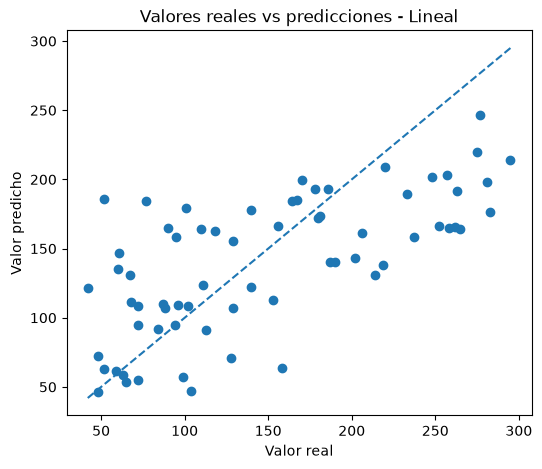

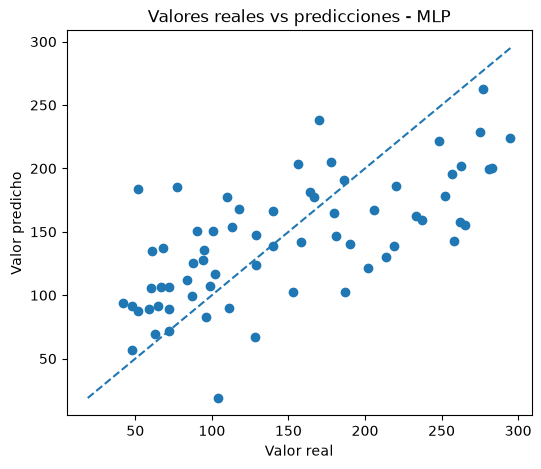

In [74]:
# Visualización de resultados para los modelos Lineal y MLP
for nombre in ["Lineal", "MLP"]:

    pred = predicciones_reg[nombre]

    plt.figure(figsize=(6, 5))

    plt.scatter(y_test_reg, pred)

    minimo = min(
        y_test_reg.min(),
        pred.min()
    )

    maximo = max(
        y_test_reg.max(),
        pred.max()
    )

    # Línea ideal: real = predicho
    plt.plot(
        [minimo, maximo],
        [minimo, maximo],
        linestyle="--"
    )

    plt.xlabel("Valor real")
    plt.ylabel("Valor predicho")
    plt.title(f"Valores reales vs predicciones - {nombre}")

    plt.show()

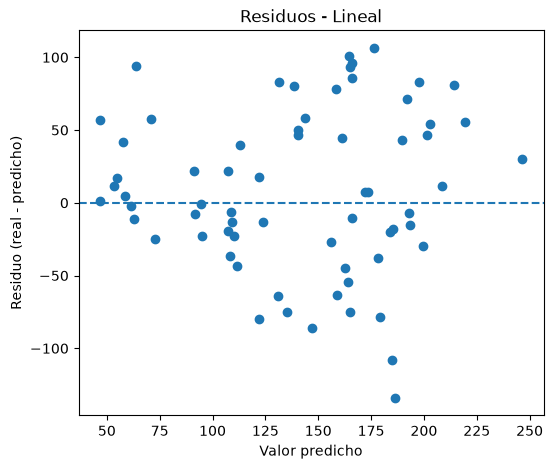

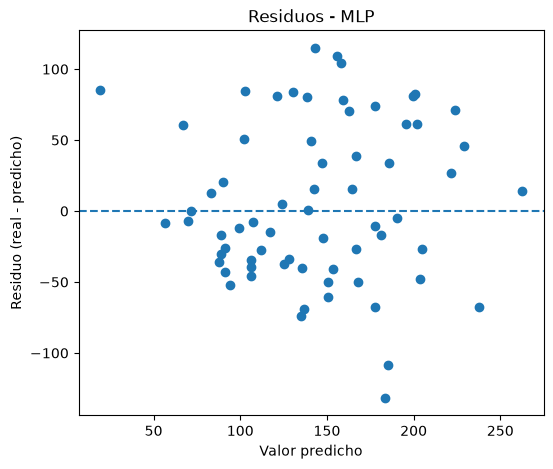

In [75]:
# Visualización de residuos para los modelos Lineal y MLP
for nombre in ["Lineal", "MLP"]:

    pred = predicciones_reg[nombre]

    residuos = y_test_reg - pred

    plt.figure(figsize=(6, 5))

    plt.scatter(pred, residuos)

    plt.axhline(
        y=0,
        linestyle="--"
    )

    plt.xlabel("Valor predicho")
    plt.ylabel("Residuo (real - predicho)")
    plt.title(f"Residuos - {nombre}")

    plt.show()

In [76]:
# Funcion para los errores 
def mayores_errores(nombre, cantidad=2):

    pred = predicciones_reg[nombre]

    errores_abs = np.abs(
        y_test_reg - pred
    )

    indices = np.argsort(
        errores_abs
    )[-cantidad:][::-1]

    resultado = pd.DataFrame(
        X_test_reg[indices],
        columns=diabetes.feature_names
    )

    resultado["Real"] = y_test_reg[indices]
    resultado["Predicción"] = pred[indices]
    resultado["Error absoluto"] = errores_abs[indices]

    return resultado

In [77]:
mayores_errores("Lineal")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Real,Predicción,Error absoluto
0,0.016281,-0.044642,0.026128,0.058608,-0.060735,-0.044215,-0.013948,-0.033958,-0.051404,-0.025930,52.0,186.145463,134.145463
1,0.038076,0.050680,-0.018062,0.066629,-0.051103,-0.016658,-0.076536,0.034309,-0.011897,-0.013504,77.0,184.729243,107.729243


In [78]:
mayores_errores("MLP")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Real,Predicción,Error absoluto
0,0.016281,-0.044642,0.026128,0.058608,-0.060735,-0.044215,-0.013948,-0.033958,-0.051404,-0.025930,52.0,183.732243,131.732243
1,-0.060003,-0.044642,0.001339,-0.029770,-0.007073,-0.021669,0.011824,-0.002592,0.031812,-0.054925,258.0,143.130504,114.869496


## Interpretación de los modelos de regresión

1. ¿Qué modelo tuvo mejor desempeño?

Random Forest presentó el mejor desempeño general en prueba según RMSE y R², con un RMSE cercano a 54.1 y un R² aproximado de 0.48. La regresión lineal obtuvo un MAE ligeramente menor. Por ello, la elección del mejor modelo depende también de la métrica considerada.

2. ¿Por qué MAE y RMSE pueden favorecer modelos distintos?

MAE pondera proporcionalmente todos los errores absolutos, mientras que RMSE eleva los errores al cuadrado antes de promediarlos. Por ello, RMSE penaliza más fuertemente los errores grandes. Un modelo puede tener un error típico ligeramente menor y ganar en MAE, mientras otro evita mejor los errores extremos y obtiene menor RMSE.

3. ¿Qué significa un R² negativo?

Un R² negativo indica que el modelo obtiene un error cuadrático mayor que el de un baseline que simplemente predijera la media del objetivo para todos los casos. No debe interpretarse como una “precisión negativa”.

4. Efecto de la regularización
Al aumentar la regularización disminuyó la magnitud de los coeficientes. En Lasso también aumentó el número de coeficientes exactamente nulos. Una regularización moderada mejoró el desempeño de validación, pero una penalización excesiva produjo subajuste y aumentó considerablemente el error.

5. ¿Qué puede explicar errores grandes?

Los errores grandes pueden corresponder a observaciones difíciles de representar mediante las relaciones aprendidas por el modelo, combinaciones de características poco frecuentes, ruido, variables relevantes que no están incluidas en el dataset o relaciones que el modelo no captura adecuadamente. Observar un caso particular permite formular hipótesis, pero no identificar por sí solo la causa del error.

6. ¿Un coeficiente demuestra causalidad?

No. Un coeficiente aprendido representa una relación predictiva dentro del modelo y los datos disponibles. Que una variable tenga un coeficiente alto no demuestra que modificar esa variable cause un cambio en el objetivo. Para establecer causalidad se necesita un diseño causal adecuado y controlar posibles variables de confusión.